In [1]:
import os
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("ggplot")
%matplotlib inline

from tqdm import tqdm_notebook, tnrange
from itertools import chain
from skimage.io import imread, imshow, concatenate_images
from skimage.transform import resize
from skimage.morphology import label
from sklearn.model_selection import train_test_split

import tensorflow as tf

from keras.models import Model, load_model
from keras.layers import Input, BatchNormalization, Activation, Dense, Dropout
from keras.layers.core import Lambda, RepeatVector, Reshape
from keras.layers.convolutional import Conv2D, Conv2DTranspose
from keras.layers.pooling import MaxPooling2D, GlobalMaxPool2D
from keras.layers.merge import concatenate, add
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from keras.optimizers import Adam
from keras.preprocessing.image import ImageDataGenerator, array_to_img, img_to_array, load_img

# New Section

In [2]:
im_width = 64
im_height = 64
border = 5

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
ids = next(os.walk("/content/drive/My Drive/docu_detect/docu500"))[2] # list of names all images in the given path
print("No. of images = ", len(ids))

No. of images =  500


In [5]:
X = np.zeros((len(ids), im_height, im_width, 1), dtype=np.float32)
y = np.zeros((len(ids), im_height, im_width, 1), dtype=np.float32)

In [6]:
# tqdm is used to display the progress bar
for n, id_ in tqdm_notebook(enumerate(ids), total=len(ids)):
    # Load images
    img = load_img("/content/drive/My Drive/docu_detect/docu500/"+id_, grayscale=True)
    x_img = img_to_array(img)
    #x_img = resize(x_img, (64, 64, 1), mode = 'constant', preserve_range = True)
    # Load masks
    mask = img_to_array(load_img("/content/drive/My Drive/docu_detect/docu_mask200/"+id_, grayscale=True))
    #mask = resize(mask, (128, 128, 1), mode = 'constant', preserve_range = True)
    # Save images
    X[n] = x_img/255.0
    y[n] = mask/255.0   

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:2: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  


/usr/local/lib/python3.7/dist-packages/keras_preprocessing/image/utils.py:107: UserWarning: grayscale is deprecated. Please use color_mode = "grayscale"
  warnings.warn('grayscale is deprecated. Please use '


In [7]:
# Split train and valid
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

Text(0.5, 1.0, 'Seg Document')

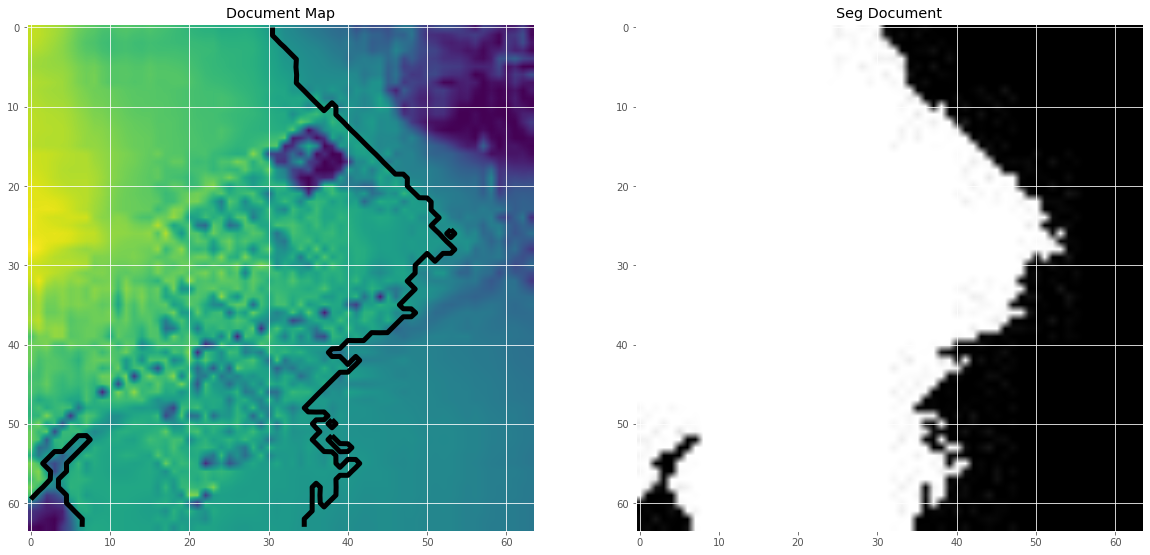

In [8]:
# Visualize any randome image along with the mask
ix = random.randint(0, len(X_train))
has_mask = y_train[ix].max() > 0 # salt indicator

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (20, 15))

ax1.imshow(X_train[ix, ..., 0], interpolation = 'bilinear')
if has_mask: # if salt
    # draw a boundary(contour) in the original image separating salt and non-salt areas
    ax1.contour(y_train[ix].squeeze(), colors = 'k', linewidths = 5, levels = [0.5])
ax1.set_title('Document Map')

ax2.imshow(y_train[ix].squeeze(), cmap = 'gray', interpolation = 'bilinear')
ax2.set_title('Seg Document')

In [9]:
#implementing ALEXNET

inputs=tf.keras.layers.Input((im_height,im_width,1))
c1=Conv2D(filters = 96, kernel_size = (11, 11),strides=(4,4),kernel_initializer = 'he_normal', padding = 'same')(inputs)
c1=Activation('relu')(c1)
p1 = MaxPooling2D((2, 2))(c1)
p1=BatchNormalization()(p1)

c2=Conv2D(filters = 256, kernel_size = (11, 11),strides=(1,1),kernel_initializer = 'he_normal', padding = 'same')(p1)
c2=Activation('relu')(c2)
p2= MaxPooling2D((2, 2))(c2)
p2=BatchNormalization()(p2)


c3=Conv2D(filters = 384, kernel_size = (3,3),strides=(1,1),kernel_initializer = 'he_normal', padding = 'same')(p2)
c3=Activation('relu')(c3)
p3= MaxPooling2D((2, 2))(c3)
p3=BatchNormalization()(p3)


c4=Conv2D(filters = 384, kernel_size = (3, 3),strides=(1,1),kernel_initializer = 'he_normal', padding = 'same')(p3)
c4=Activation('relu')(c4)
p4 = MaxPooling2D((2, 2))(c4)
p4=BatchNormalization()(p4)

u5=Conv2DTranspose(384, (3, 3), strides = (2, 2), padding = 'same')(p4)
u5=Activation('relu')(u5)
u5=BatchNormalization()(u5)
u5=Dropout(0.1)(u5)

u6=Conv2DTranspose(384, (3, 3), strides = (2, 2), padding = 'same')(u5)
u6=Activation('relu')(u6)
u6=BatchNormalization()(u6)
u6=Dropout(0.1)(u6)


u7=Conv2DTranspose(256, (11,11), strides = (2, 2), padding = 'same')(u6)
u7=Activation('relu')(u7)
u7=BatchNormalization()(u7)
u7=Dropout(0.1)(u7)

u8=Conv2DTranspose(96, (11,11), strides = (2, 2), padding = 'same')(u7)
u8=Activation('relu')(u8)
u8=BatchNormalization()(u8)
u8=Dropout(0.1)(u8)

u9=Conv2DTranspose(96, (11,11), strides = (2, 2), padding = 'same')(u8)
u9=Activation('relu')(u9)
u9=BatchNormalization()(u9)
u9=Dropout(0.1)(u9)

u10=Conv2DTranspose(96, (11,11), strides = (2, 2), padding = 'same')(u9)
u10=Activation('relu')(u10)
u10=BatchNormalization()(u10)
u10=Dropout(0.1)(u10)
outputs = Conv2D(1, (1, 1), activation='sigmoid')(u10)
model = Model(inputs=[inputs], outputs=[outputs])
model.compile(optimizer='adam', loss='binary_crossentropy',metrics=['accuracy'])
model.summary()

   


Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 64, 64, 1)]       0         
_________________________________________________________________
conv2d (Conv2D)              (None, 16, 16, 96)        11712     
_________________________________________________________________
activation (Activation)      (None, 16, 16, 96)        0         
_________________________________________________________________
max_pooling2d (MaxPooling2D) (None, 8, 8, 96)          0         
_________________________________________________________________
batch_normalization (BatchNo (None, 8, 8, 96)          384       
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 8, 8, 256)         2973952   
_________________________________________________________________
activation_1 (Activation)    (None, 8, 8, 256)         0     

In [10]:
model.summary()

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 64, 64, 1)]       0         
_________________________________________________________________
conv2d (Conv2D)              (None, 16, 16, 96)        11712     
_________________________________________________________________
activation (Activation)      (None, 16, 16, 96)        0         
_________________________________________________________________
max_pooling2d (MaxPooling2D) (None, 8, 8, 96)          0         
_________________________________________________________________
batch_normalization (BatchNo (None, 8, 8, 96)          384       
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 8, 8, 256)         2973952   
_________________________________________________________________
activation_1 (Activation)    (None, 8, 8, 256)         0     

In [11]:
callbacks = [
    EarlyStopping(patience=10, verbose=1),
    ReduceLROnPlateau(factor=0.1, patience=5, min_lr=0.00001, verbose=1),
    ModelCheckpoint('model-hair.h5', verbose=1, save_best_only=True, save_weights_only=True)
]

In [12]:
results = model.fit(X_train, y_train, batch_size=32, epochs=100, \
                    validation_data=(X_valid, y_valid))

Epoch 1/100
13/13 [==============================] - 40s 309ms/step - loss: 0.9337 - accuracy: 0.5830 - val_loss: 5.7543 - val_accuracy: 0.2845
Epoch 2/100
13/13 [==============================] - 2s 117ms/step - loss: 0.4444 - accuracy: 0.7367 - val_loss: 3.6197 - val_accuracy: 0.4550
Epoch 3/100
13/13 [==============================] - 2s 118ms/step - loss: 0.3741 - accuracy: 0.7502 - val_loss: 1.7086 - val_accuracy: 0.6397
Epoch 4/100
13/13 [==============================] - 2s 118ms/step - loss: 0.3245 - accuracy: 0.7718 - val_loss: 4.0202 - val_accuracy: 0.3485
Epoch 5/100
13/13 [==============================] - 2s 118ms/step - loss: 0.3075 - accuracy: 0.7755 - val_loss: 3.2669 - val_accuracy: 0.4096
Epoch 6/100
13/13 [==============================] - 2s 118ms/step - loss: 0.2583 - accuracy: 0.7981 - val_loss: 2.6600 - val_accuracy: 0.4969
Epoch 7/100
13/13 [==============================] - 2s 118ms/step - loss: 0.2582 - accuracy: 0.7966 - val_loss: 1.2133 - val_accuracy: 0.654

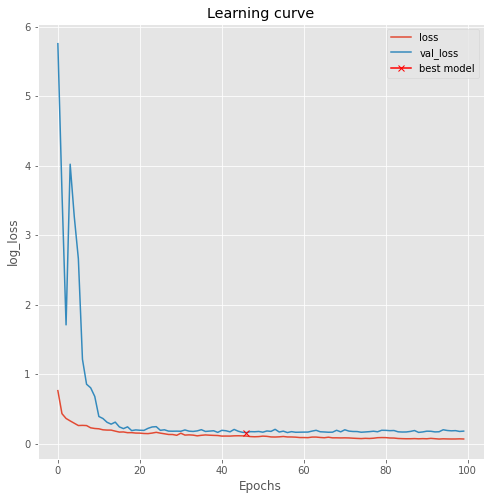

In [15]:
plt.figure(figsize=(8, 8))
plt.title("Learning curve")
plt.plot(results.history["loss"], label="loss")
plt.plot(results.history["val_loss"], label="val_loss")
plt.plot( np.argmin(results.history["val_loss"]), np.min(results.history["val_loss"]), marker="x", color="r", label="best model")
plt.xlabel("Epochs")
plt.ylabel("log_loss")
plt.legend();

In [16]:
model.evaluate(X_valid, y_valid, verbose=1)

4/4 [==============================] - 0s 41ms/step - loss: 0.1796 - accuracy: 0.8301


[0.17960114777088165, 0.8300854563713074]

In [17]:
preds_train = model.predict(X_train, verbose=1)
preds_val = model.predict(X_valid, verbose=1)

4/4 [==============================] - 0s 34ms/step


In [18]:
preds_train_t = (preds_train > 0.5).astype(np.uint8)
preds_val_t = (preds_val > 0.5).astype(np.uint8)

In [19]:
def plot_sample(X, y, preds, binary_preds, ix=None):
    """Function to plot the results"""
    if ix is None:
        ix = random.randint(0, len(X))

    has_mask = y[ix].max() > 0

    fig, ax = plt.subplots(1, 4, figsize=(20, 10))
    #ax[0].imshow(X[ix, ..., 0], cmap='seismic')
    ax[0].imshow(X[ix, ..., 0])
    #if has_mask:
        #ax[0].contour(y[ix].squeeze(), colors='k', levels=[0.5])
    ax[0].set_title('document Heatmap')

    ax[1].imshow(y[ix].squeeze())
    ax[1].set_title('Document')

    ax[2].imshow(preds[ix].squeeze(), vmin=0, vmax=1)
    if has_mask:
        ax[2].contour(y[ix].squeeze(), colors='k', levels=[0.5])
    ax[2].set_title('document detected')
    
    ax[3].imshow(binary_preds[ix].squeeze(), vmin=0, vmax=1)
    if has_mask:
        ax[3].contour(y[ix].squeeze(), colors='k', levels=[0.5])
    ax[3].set_title('Document Predicted binary');

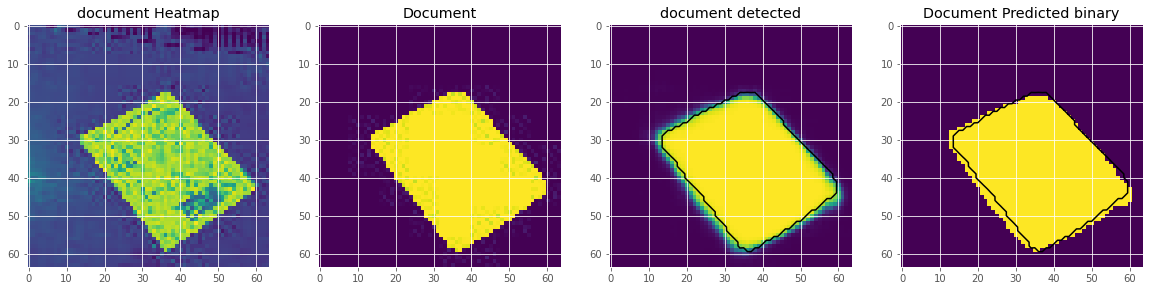

In [20]:
# Check if training data looks all right
plot_sample(X_train, y_train, preds_train, preds_train_t, ix=15)

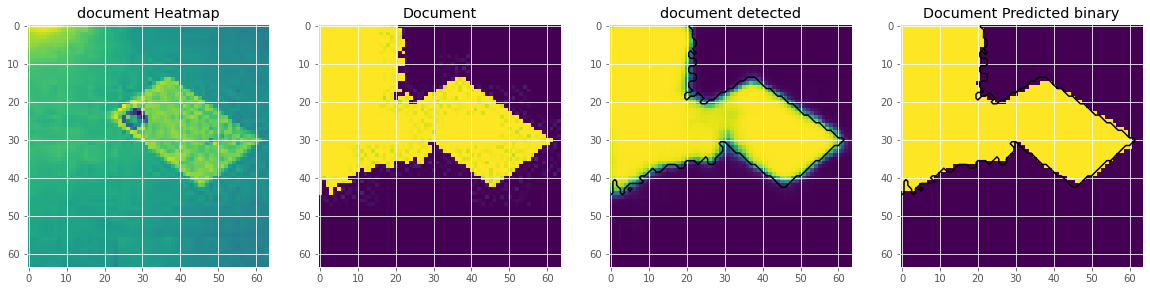

In [21]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

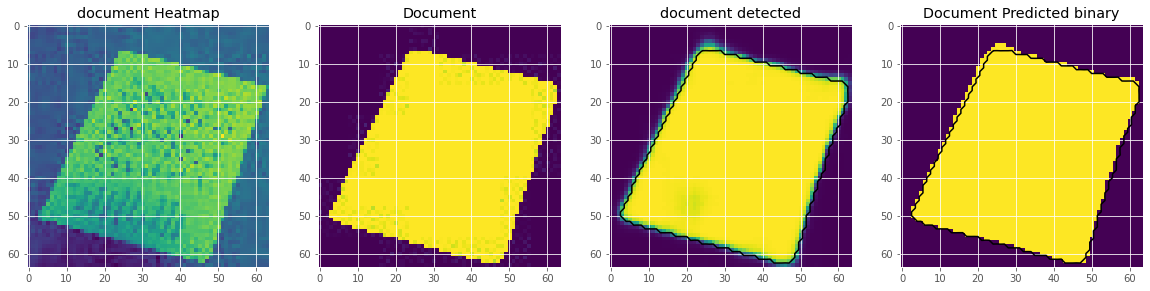

In [22]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

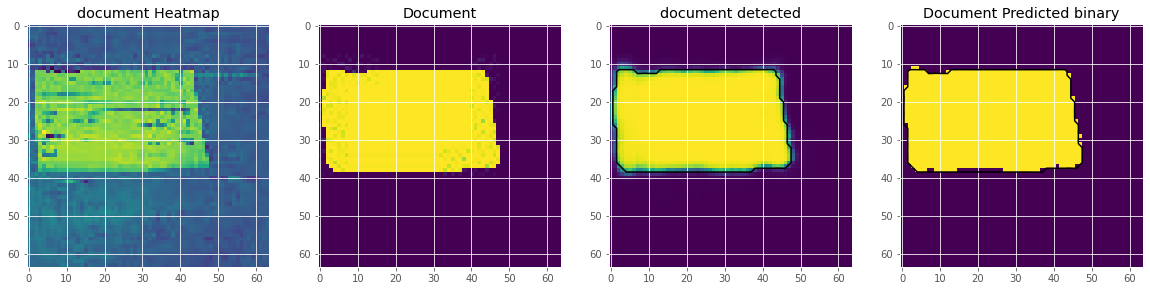

In [23]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

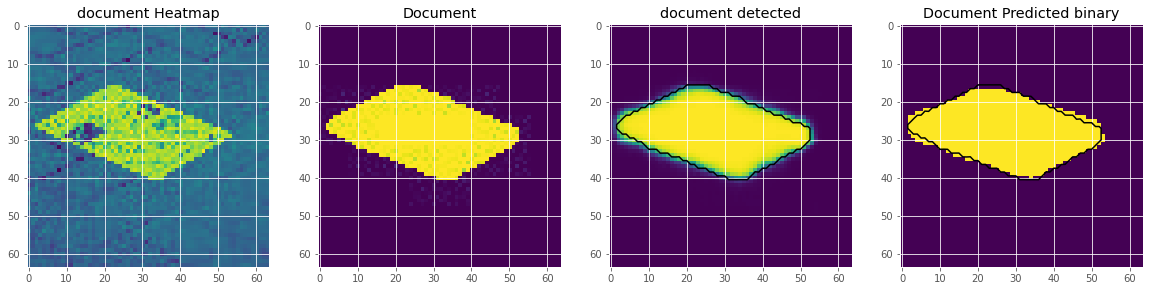

In [24]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

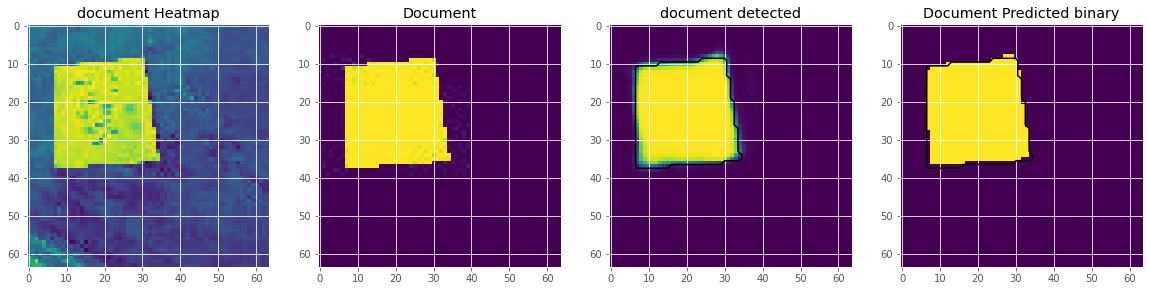

In [25]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

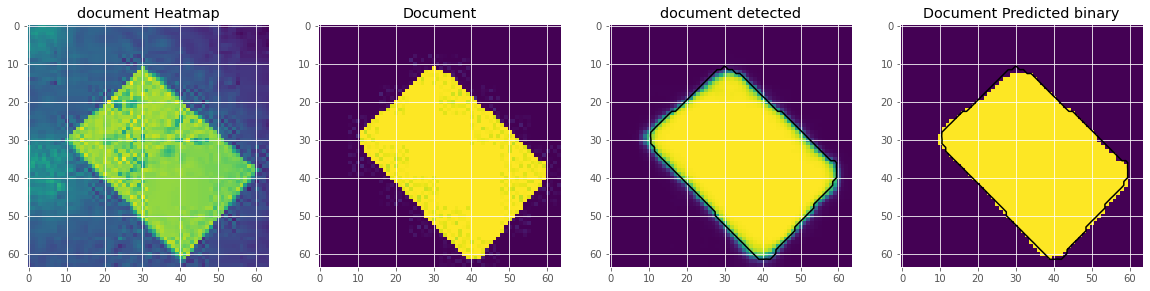

In [26]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

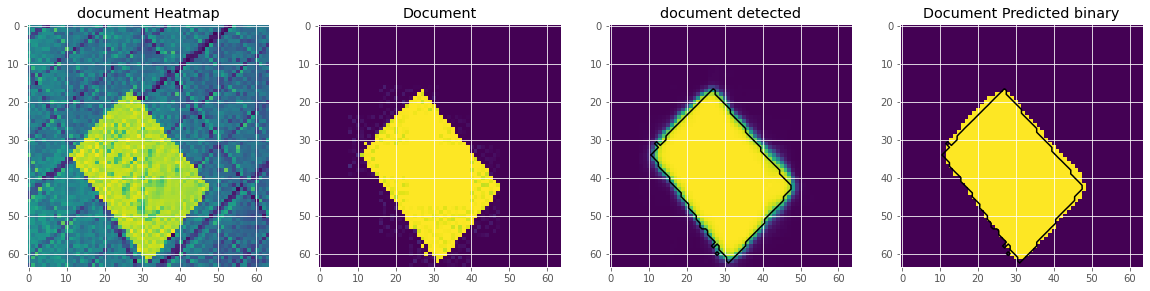

In [27]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

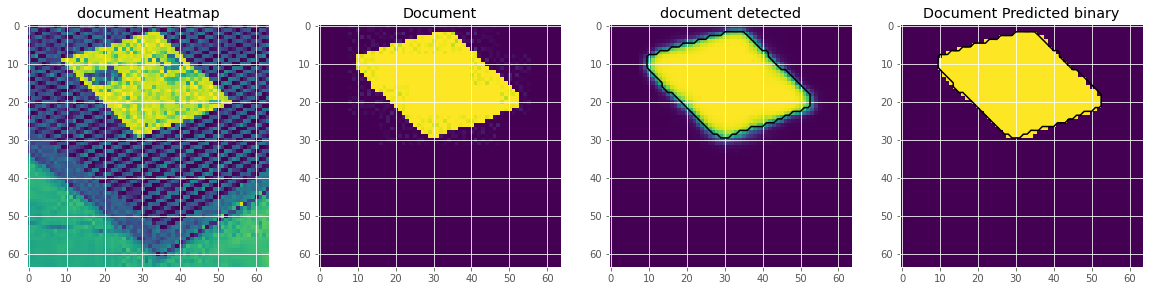

In [28]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

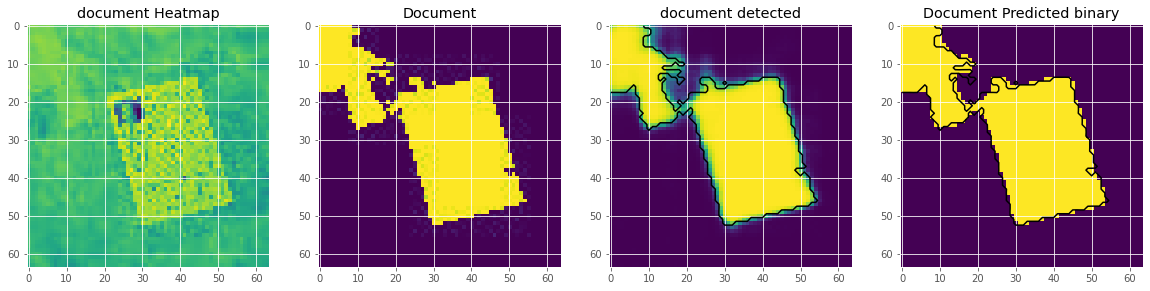

In [29]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

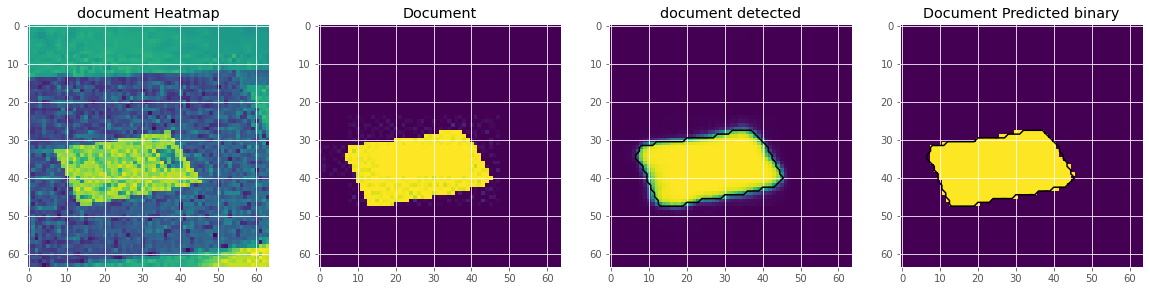

In [30]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

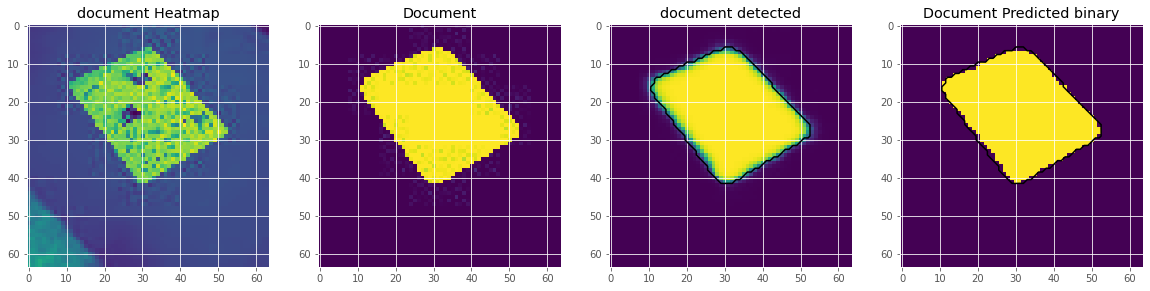

In [31]:
plot_sample(X_train, y_train, preds_train, preds_train_t)

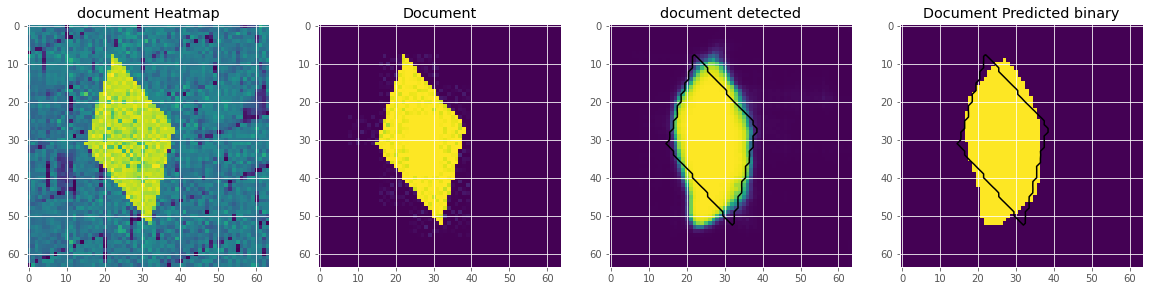

In [32]:
# Check if valid data looks all right
plot_sample(X_valid, y_valid, preds_val, preds_val_t, ix=4)

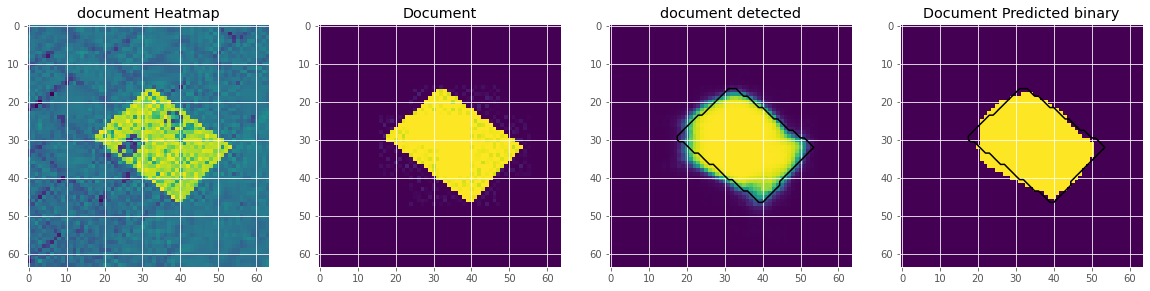

In [33]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

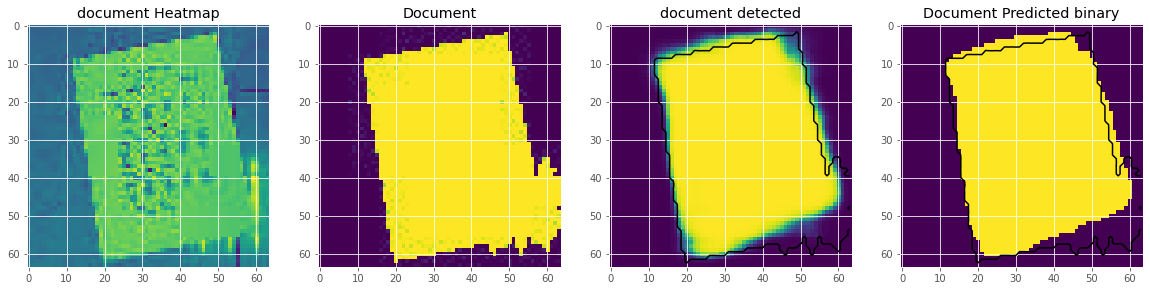

In [34]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

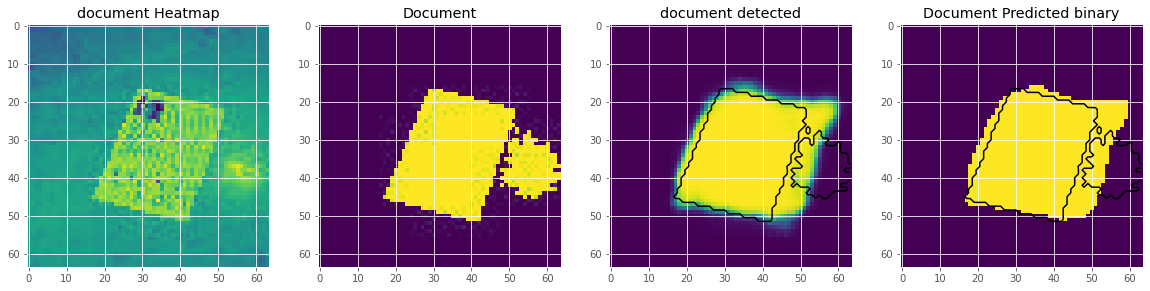

In [35]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

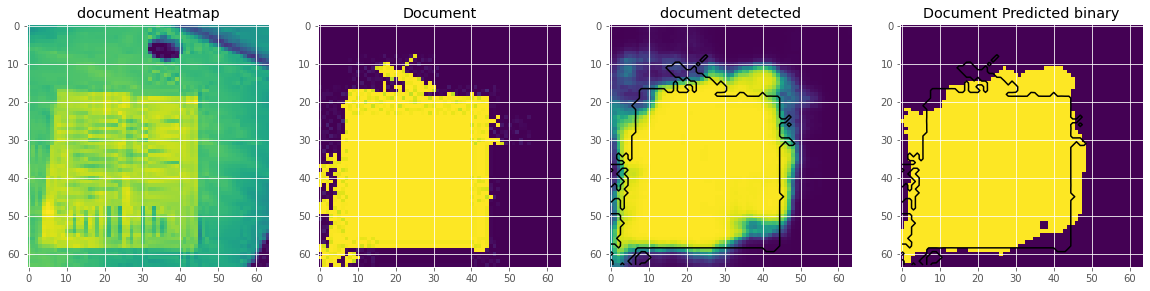

In [36]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

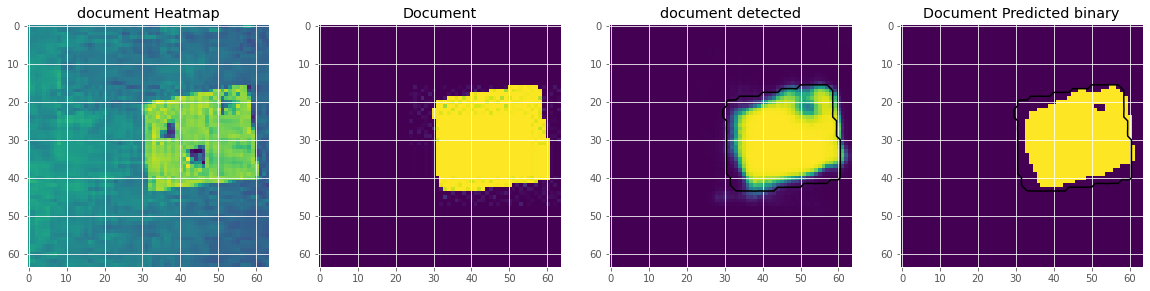

In [37]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

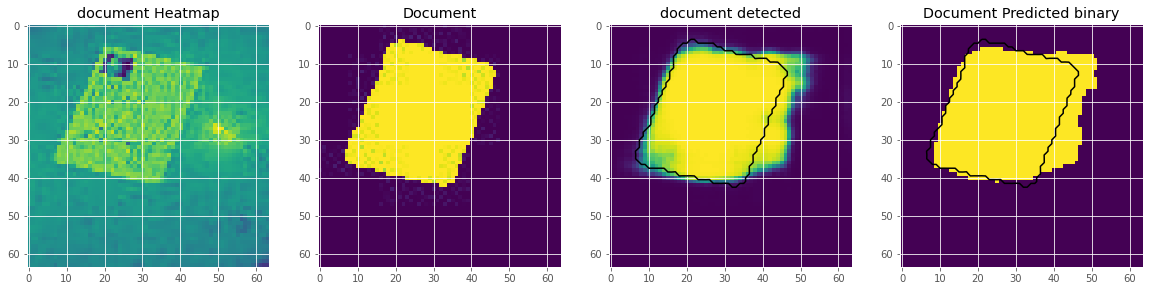

In [38]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

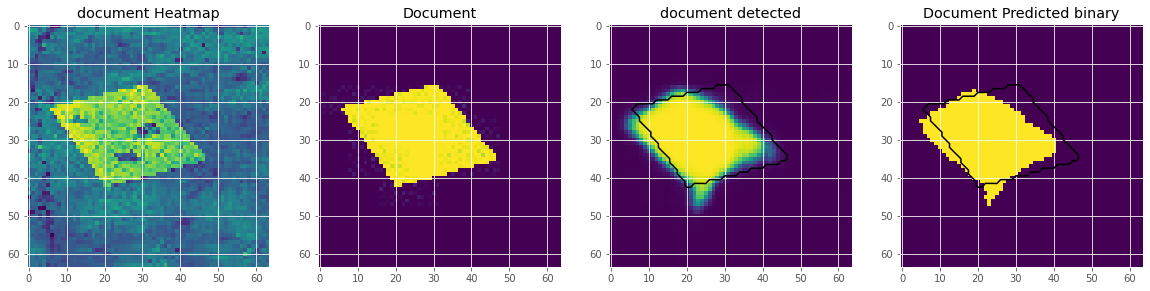

In [39]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

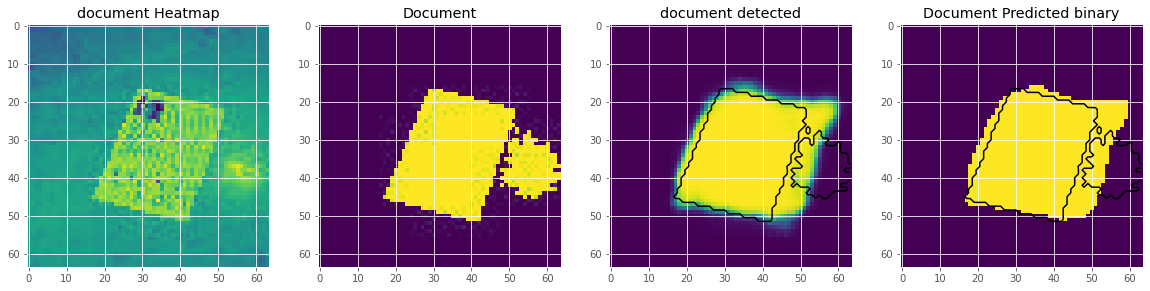

In [40]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

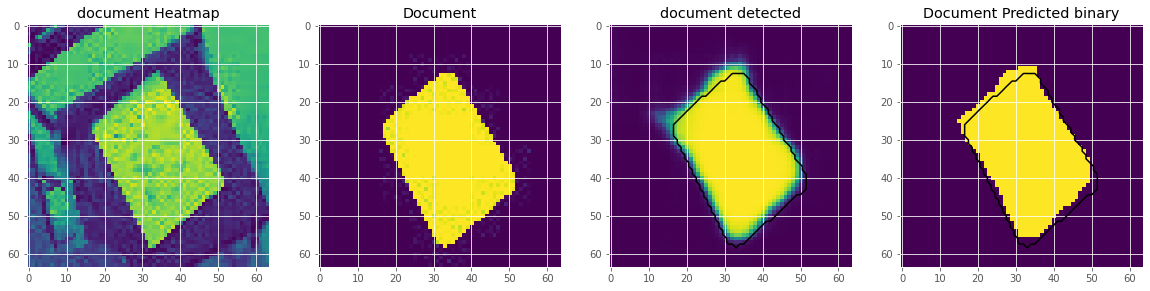

In [41]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

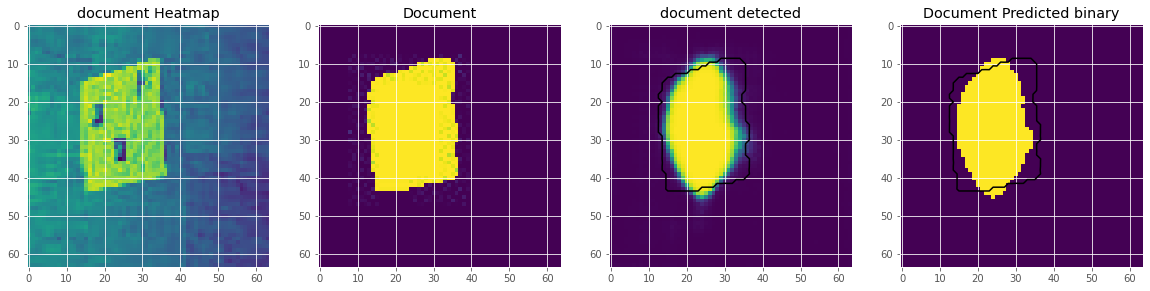

In [42]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

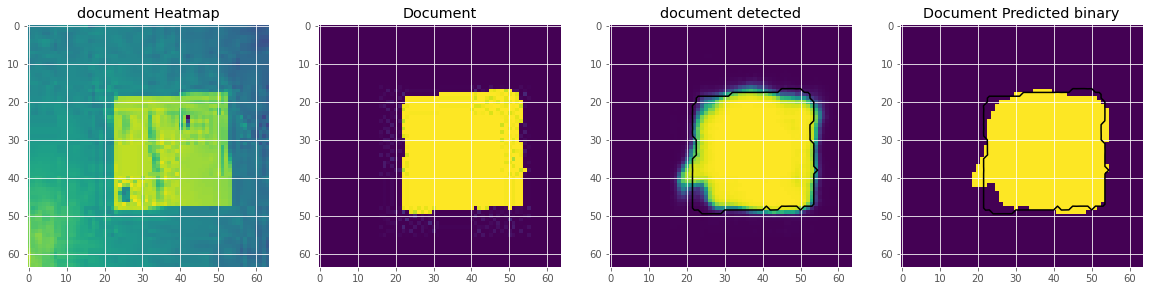

In [43]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

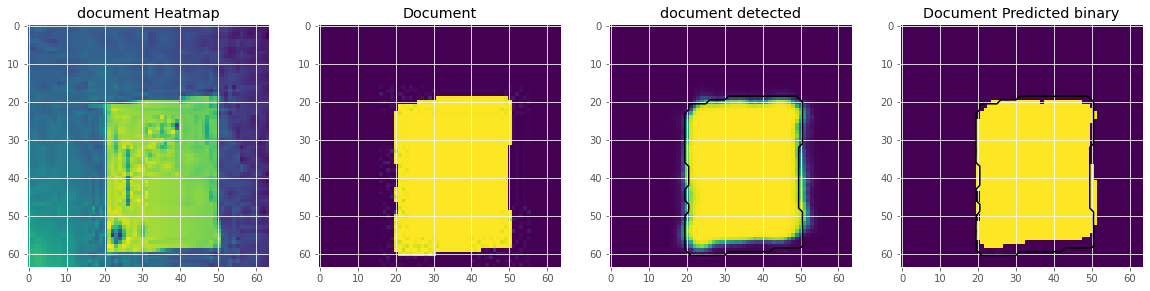

In [44]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

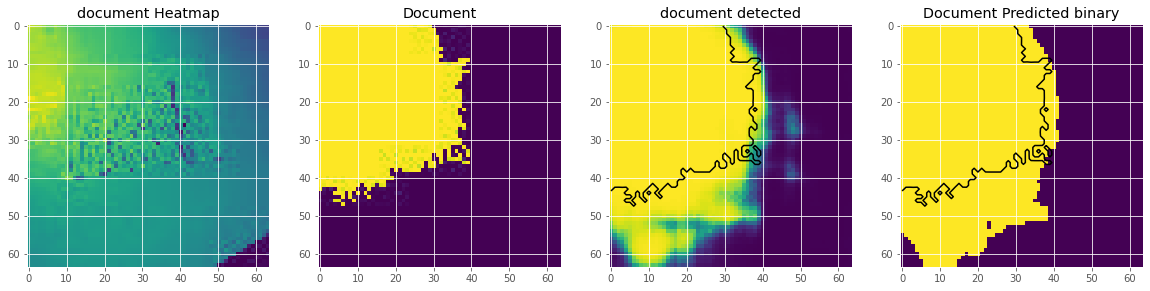

In [45]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)

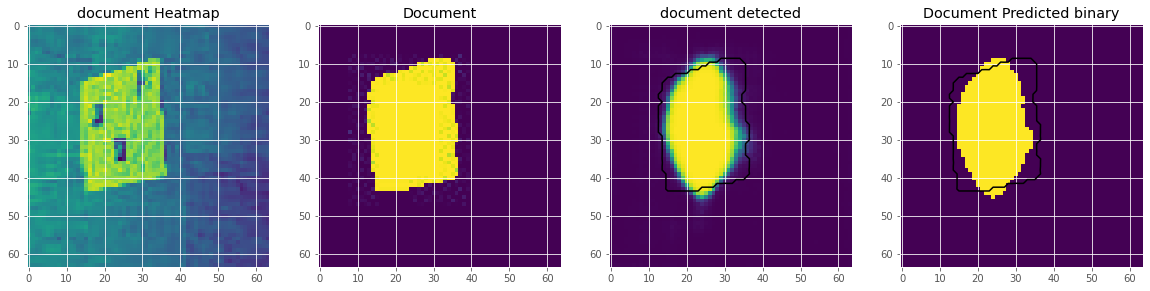

In [46]:
plot_sample(X_valid, y_valid, preds_val, preds_val_t)